# SeismicDataset. Подготовка сейсмического датасета #

## 1.1. Исходные модели и постановка исследования ##

Как описана среда и какой физический вопрос возникает при переходе от растровой модели к расчёту волн?

In [1]:
from IPython.display import Image, display

from scripts.project_paths import PROJECT_ROOT as ROOT
from scripts.reporting import dataset_summaries

### Письмо Василия Костенчука ###

Первоначальное задание приводим целиком с исходным написанием. [Текст письма](src/vasily_message.txt).

> два архива, это два разных датасета - с прямыми (flat / EFVB)  и кривыми (curved/ ECVB)  слоями
>
> в каждом по 30к+30к файлов, соотвествующих 30к разным гео-конфигурациям
>
> для каждой конфигурации два файла VP и VS, с распределениями соответствующих скоростей волн (в м/c). Данные лежат просто plain-текстом, массивами 70x70. 
>
> Плотность среды предполагается постоянной по всему объему и равной 1000 кг/м3.
>
> ячейки - равномерные квадратные 10м x 10м.  Т.е. вся область 700x700 м2 (вообще небольшая).
>
> Предлагаю предполагать, что данные массивы соответствуют свойствам среды в ячейке (не в узлах), а узлов, соответственно 71x71
>
> данные в файлах идут сверху-вниз (т.е. первая строка - самый верхний слой, последняя - самый нижний)
>
> так, что еще нужно для расчета...
>
> решаем 5 задач, для 5 разных позиций источников. Источники расположены на верхней границе, с координатами X  = [0, 175, 350, 525, 700] м
> в источнике задается вертикальное перемещение - U_vert (t) по формуле импульса Рикера с частотой 15Гц (амплитуду, я так понимаю, можно произвольную. Но одинаковую для всех расчетов)
>
> на выходе - U_vert(t), U_hor(t)  (Ux,Uy или Ux,Uz, смотря, как именовать оси) в 71 приемнике на поверхности. Интервал Времени  - 2 sec, с шагом 0.001 sec. Т.е. 2000 записей для каждого приемника.  Вся сейсмограмма для одного источника  - массив 71x2000, для всех 5 источников, массив 5x71x2000.
>
> Граничные условия. слева/справа/снизу  - поглощение, сверху - свободная поверхность
>
> предлагаю пока для проверки посчитать 2-3 какие-нибудь конфигурации из каждого из архивов. А потом уже запустим полный расчет
>
> весь датасет, будет весить примерно 130 гигов, на КАЖДЫЙ из двух классов (столько весят аналогичные датасеты EFWI). Т.е. места нужно много ))

### Опубликованный эксперимент EFWI ###

Восемь наборов EFWI предложены для многопараметрической обратной задачи. По горизонтальной и вертикальной компонентам поверхностной записи требуется восстановить сразу две карты скоростей. В семействе Vel буква F обозначает плоские слои, C — криволинейные, B — более сложный вариант семейства. Для каждого из EFVB и ECVB опубликованы 24 000 обучающих и 6 000 тестовых моделей. Исходные карты Vp взяты из OpenFWI. Поле коэффициента Пуассона, в том числе тонкий резервуар, задаёт дополнительную изменчивость Vs. [Каталог и ссылки на данные](https://efwi-lanl.github.io/docs/data.html) · [Статья Feng et al., NeurIPS 2023](ref/efwi_feng_2023_main.pdf).

Авторы решали двумерную задачу изотропной упругости при постоянной плотности 1 г/см³. В статье наблюдаемые обозначены как перемещения. В приложении описаны точечный импульс Рикера 15 Гц на вертикальной компоненте и конечно-разностная схема второго порядка по времени и четвёртого по пространству. Авторы указывают поглощение на 350 сеточных шагах. Подробности верхнего условия, нормировки силы и внутреннего шага интегрирования по этой публикации однозначно восстановить нельзя. [Приложение, §§ 2–3](ref/efwi_feng_2023_supplement.pdf) · [Сверка с методическими источниками и кодом](docs/dev_1_4_efwi_comparison_v1.md).

| Параметр | Опубликованный EFWI | Задание Василия | Принятая серия SEMGPU2 |
|---|---|---|---|
| Физическое ядро | 350 × 350 м, ячейка 5 м | 700 × 700 м, ячейка 10 м | 1400 × 700 м, выходная ячейка 10 × 10 м |
| Источники | 5 сверху через 87,5 м, 15 Гц | 5 сверху через 175 м, 15 Гц | целевые 13 через 100 м, сила 30 Гц |
| Приёмники | 70 через 5 м | 71 через 10 м | 140 через 10 м, в центрах по x |
| Запись одной компоненты и одного источника | 1000 × 70, 1 с | 2000 отсчётов по письму, 2 с | 1001 × 140, 1 с с обоими концами |
| Физическая величина | ux, uz по статье | перемещения | скорости Vx, Vy |

Во всех трёх случаях шаг выдачи равен 1 мс. Совпадение массива исходных скоростей ещё не задаёт ни физического масштаба модели, ни системы наблюдений.

### Что задано в одной модели ###

В исходных ZIP каждому номеру соответствуют два поля скоростей, Vp и Vs в м/с. Значения заданы в ячейках 70×70, первая строка примыкает к свободной поверхности. Плотность принята равной 1000 кг/м³. Одна пара скоростей определяет материал. Если две области с такой парой разделены другим слоем, они получают отдельные номера геометрических регионов.

### Два класса сред ###

EFVB даёт плоскопараллельные слои. В ECVB горизонты изгибаются, выклиниваются и образуют включения. На обзорах использована общая цветовая шкала. Статистика ниже охватывает все пары файлов, включая проверку числа моделей по гистограмме материалов.

EFVB: 30000 моделей, 3–10 материалов; Vp (1500.0, 4500.0), Vs (615.71051, 2995.11597) м/с
ECVB: 30000 моделей, 3–12 материалов; Vp (1500.0, 4500.0), Vs (616.98389, 2999.36597) м/с


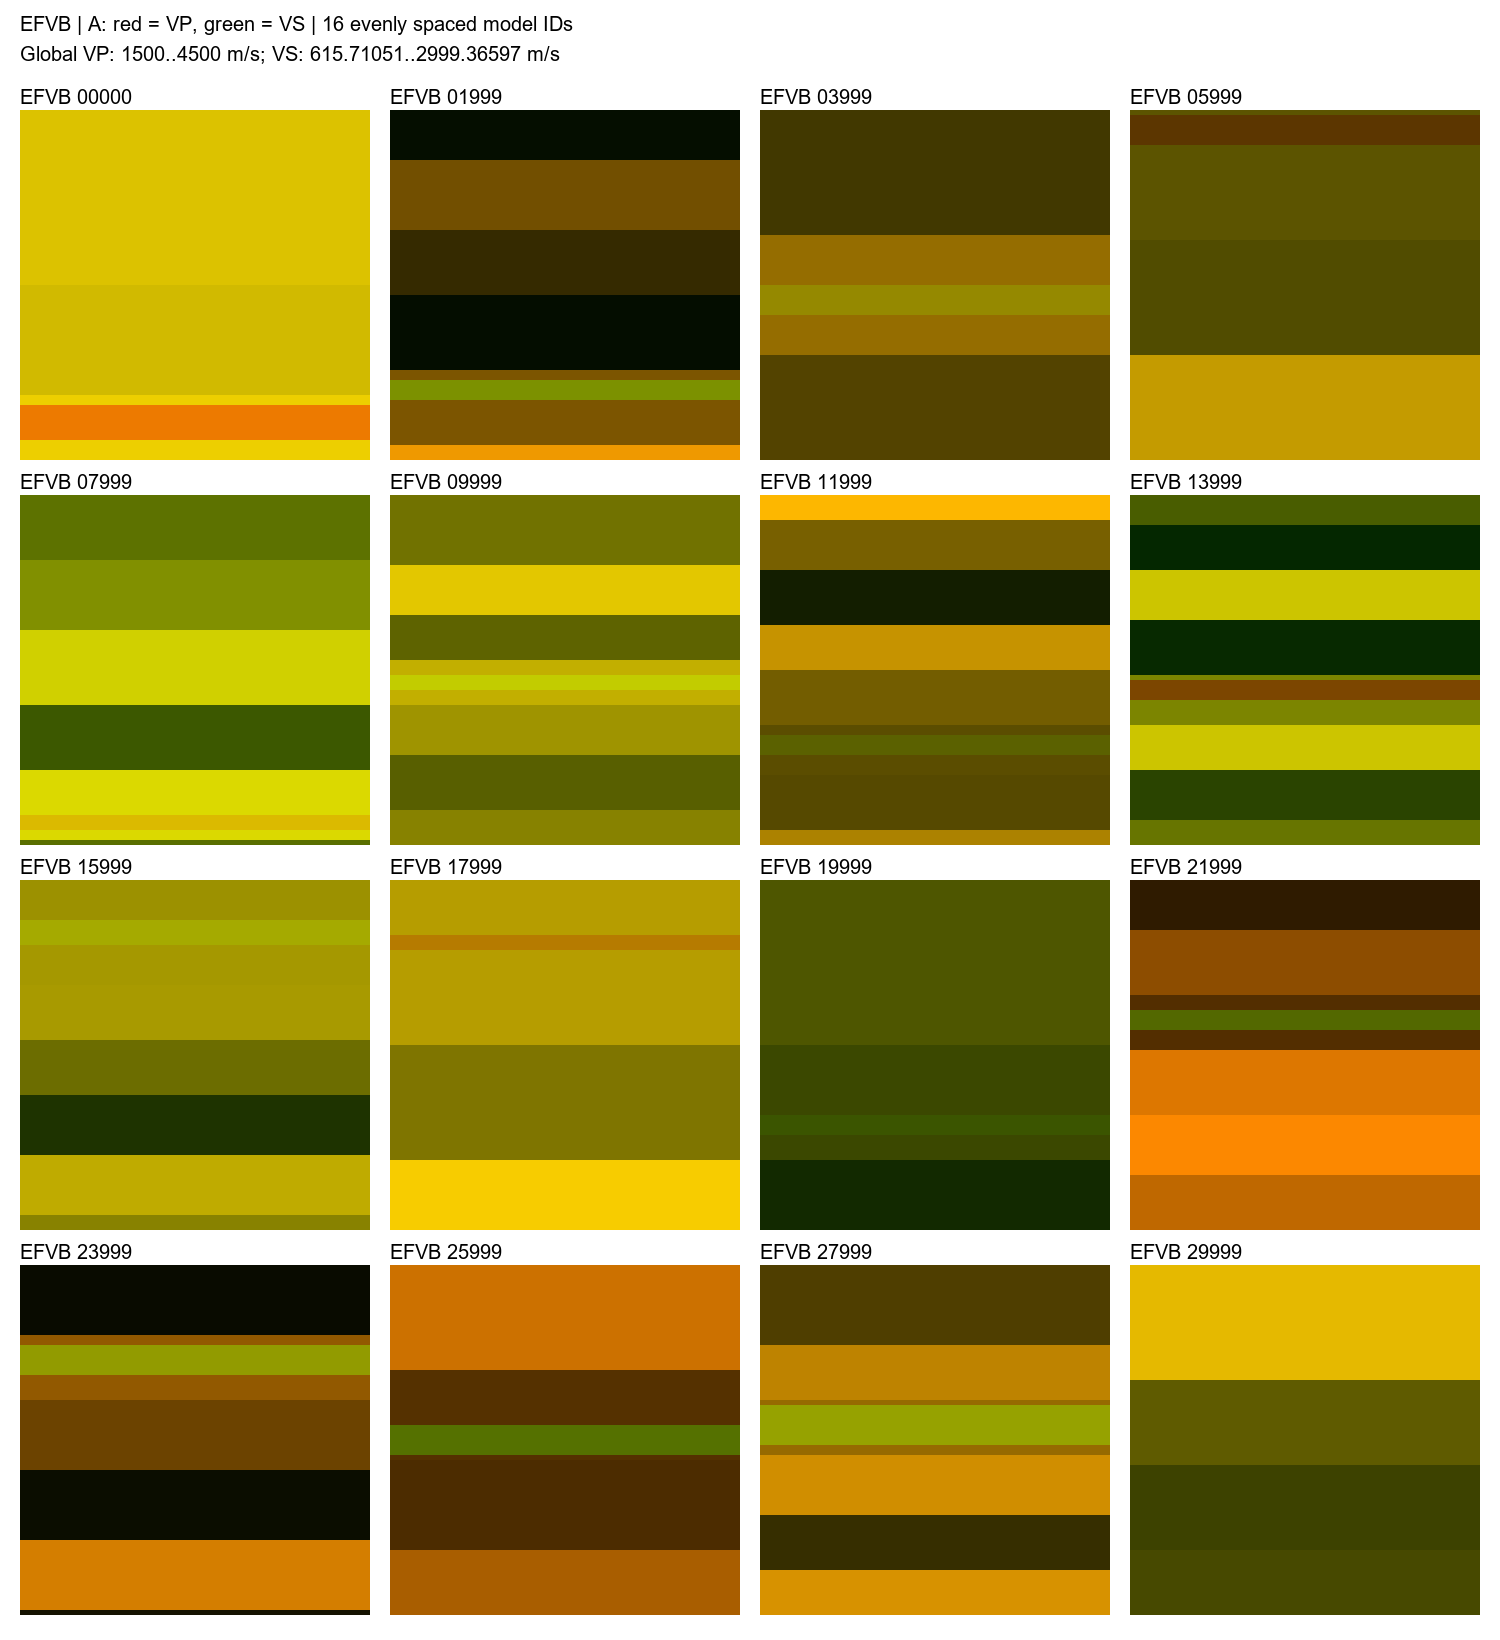

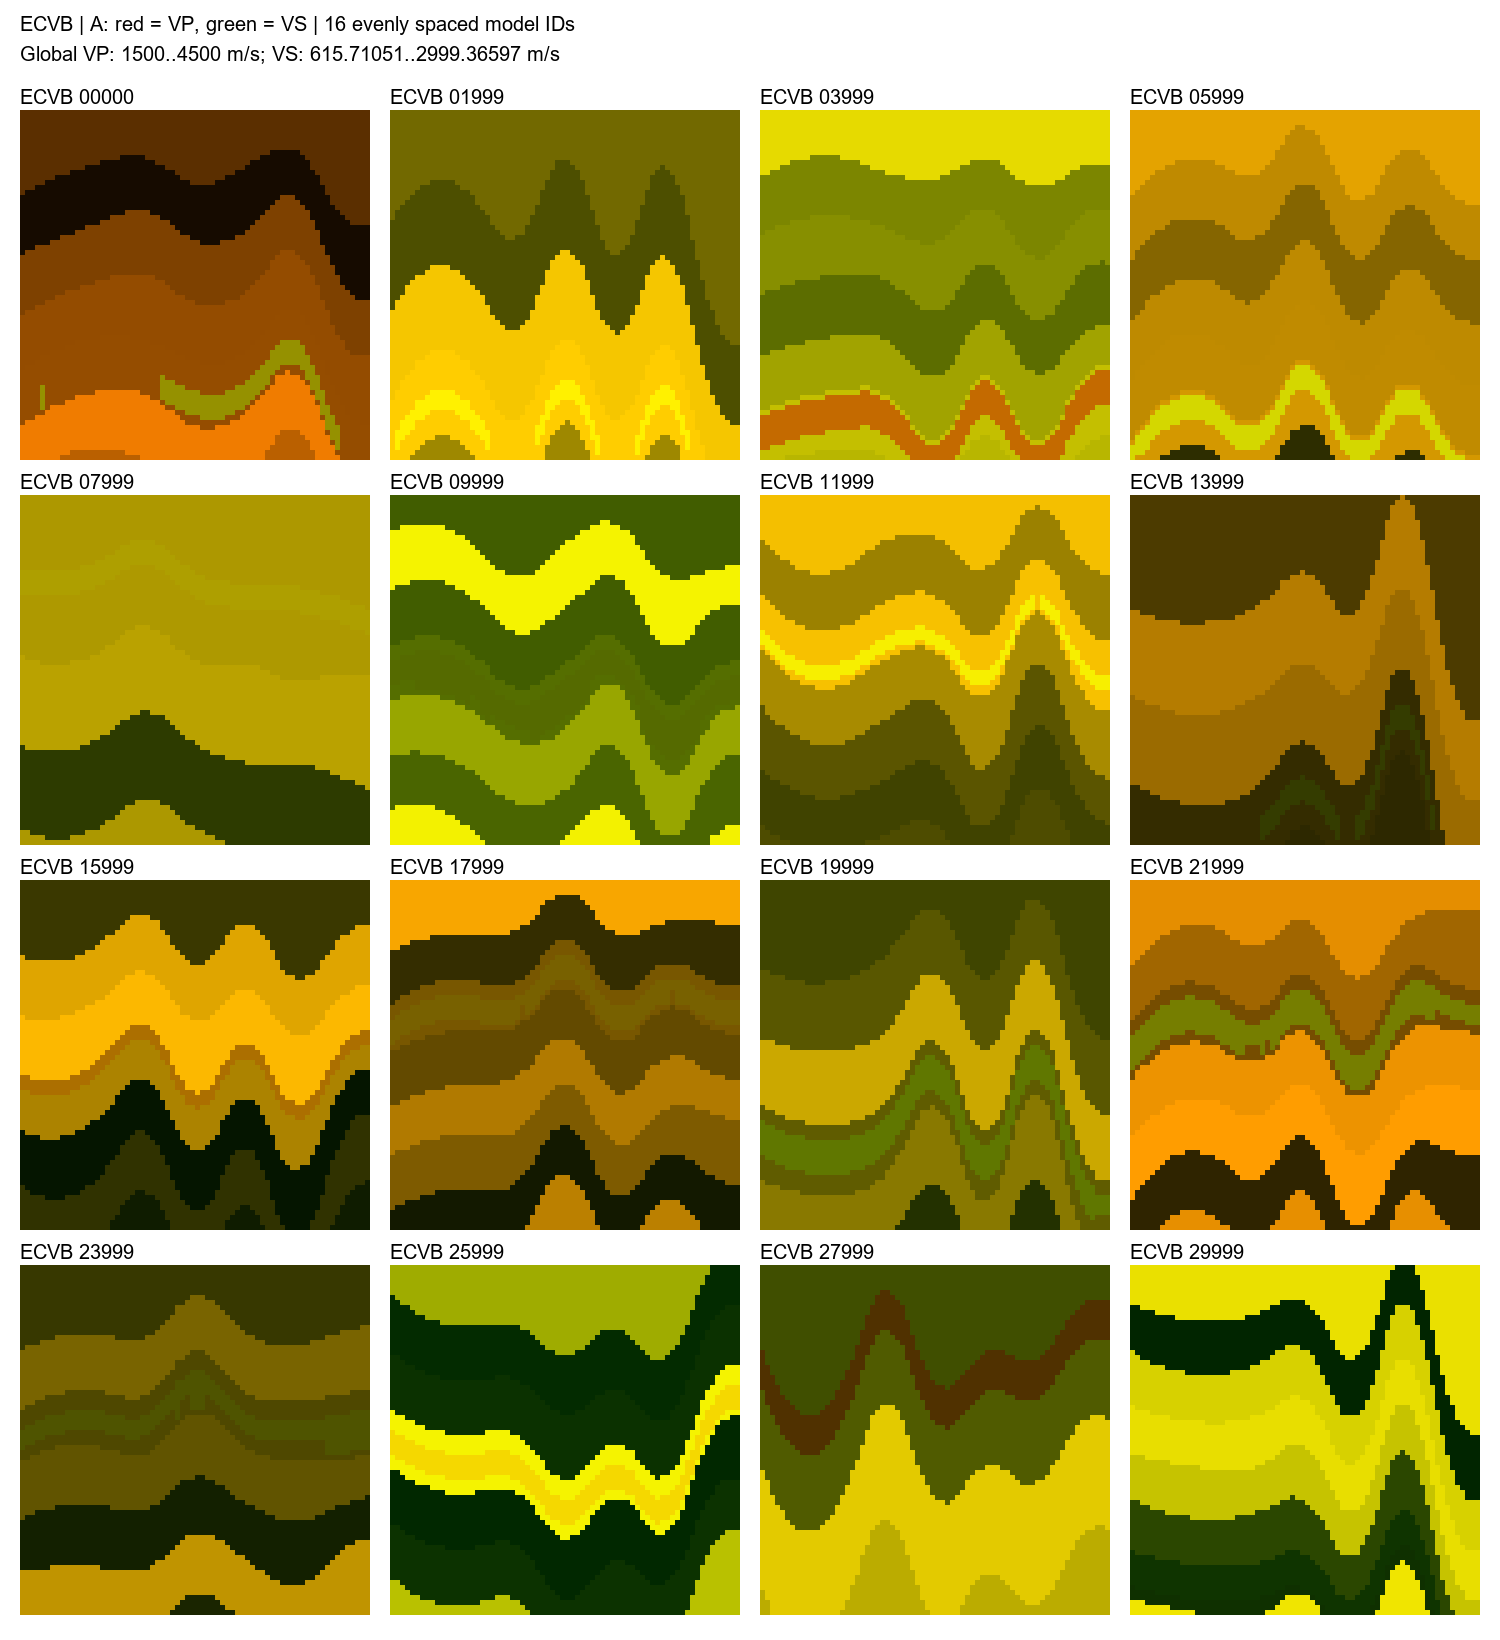

In [2]:
for group in dataset_summaries((ROOT / "data/dev_1_1_preprocessing/dataset_statistics.json")):
    print(f"{group.name}: {group.models} моделей, {group.materials[0]}–{group.materials[1]} материалов; Vp {group.vp}, Vs {group.vs} м/с")

display(Image(filename=str(ROOT / "img/dev_1_1_preprocessing/previews/A/EFVB_overview.png"), width=850))

display(Image(filename=str(ROOT / "img/dev_1_1_preprocessing/previews/A/ECVB_overview.png"), width=850))

### Масштаб и научный вопрос ###

Исходный квадрат занимает 700×700 м при шаге 10 м. В принятой впоследствии постановке те же 70 столбцов растянуты до 1400 м: ширина ячейки становится 20 м, глубина остаётся 10 м. Этот переход меняет наклоны границ и расстояния от источника до края. Ранние пилоты на квадрате служат самостоятельными опытами. Для плоского слоя растр точно передаёт горизонтальную границу, для наклонного — заменяет её ступенями. Следующая глава измеряет, насколько такая замена меняет наблюдаемый сигнал.

### Вывод ###

В 60 000 моделях одни и те же свойства заданы разной геометрией горизонтов. Плоские границы можно перенести напрямую, а для ECVB требуется проверить последствия сглаживания.